# Практична робота №1. Логістична регресія
Класифікація виконуваних файлів Windows на шкідливі та безпечні, датасет Malware Executable Detection (Kaggle).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

In [2]:
df = pd.read_csv("uci_malware_detection.csv")
X = df.drop(columns="Label")
y = (df["Label"] == "malicious").astype(int)
print("Розмір:", X.shape)
print(df["Label"].value_counts())

Розмір: (373, 531)
Label
malicious        301
non-malicious     72
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

In [4]:
model = make_pipeline(
    VarianceThreshold(0.01),
    LogisticRegression(C=0.1, max_iter=1000, class_weight="balanced"),
)
model.fit(X_train, y_train)
selected = X.columns[model[0].get_support()]
print("Ознак після відбору:", len(selected))

Ознак після відбору: 464


In [5]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["non-malicious", "malicious"]))

Accuracy: 1.0
ROC AUC: 1.0
[[18  0]
 [ 0 76]]
               precision    recall  f1-score   support

non-malicious       1.00      1.00      1.00        18
    malicious       1.00      1.00      1.00        76

     accuracy                           1.00        94
    macro avg       1.00      1.00      1.00        94
 weighted avg       1.00      1.00      1.00        94



In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring="f1")
print("F1 5-fold CV:", scores.round(3), "середнє:", round(scores.mean(), 3))

F1 5-fold CV: [1.    0.992 1.    0.992 1.   ] середнє: 0.997


In [7]:
coef = pd.Series(model[-1].coef_[0], index=selected).sort_values()
print("Intercept θ0:", round(model[-1].intercept_[0], 3))
print("Топ-5 ознак malicious:\n", coef.tail(5)[::-1].round(3))
print("Топ-5 ознак non-malicious:\n", coef.head(5).round(3))

Intercept θ0: -1.939
Топ-5 ознак malicious:
 F_20     0.309
F_53     0.212
F_250    0.210
F_526    0.193
F_530    0.182
dtype: float64
Топ-5 ознак non-malicious:
 F_19    -0.313
F_69    -0.280
F_140   -0.195
F_50    -0.181
F_66    -0.177
dtype: float64


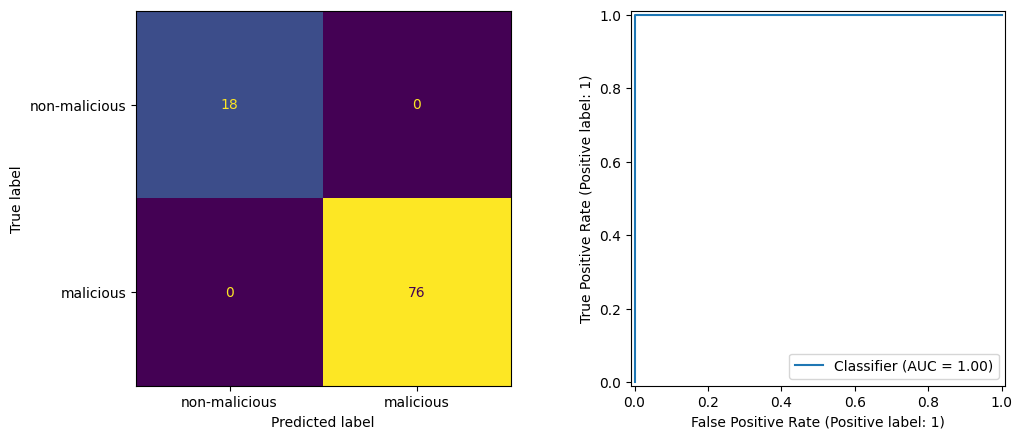

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["non-malicious", "malicious"], ax=ax[0], colorbar=False
)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
plt.tight_layout()
plt.savefig("results.png", dpi=120)
plt.show()

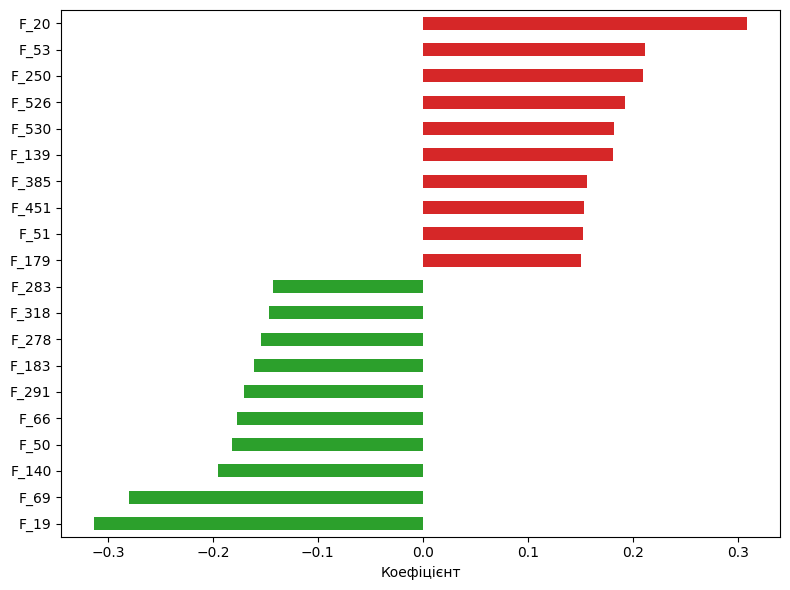

In [9]:
top = pd.concat([coef.head(10), coef.tail(10)])
plt.figure(figsize=(8, 6))
top.plot.barh(color=["tab:green"] * 10 + ["tab:red"] * 10)
plt.xlabel("Коефіцієнт")
plt.tight_layout()
plt.savefig("coef.png", dpi=120)
plt.show()